# WebOrganizer vs propella-1 labels on Nemotron-CC

**Question:** how do the labels of the WebOrganizer topic and format classifiers relate
to the propella-1 annotations of the same documents? Three pairings are of most
interest:

- WebOrganizer **format** and propella `content_type`
- WebOrganizer **topic** and propella `business_sector`
- WebOrganizer **topic** and propella `technical_content`

**Data:**

- `data/WO_labelled/WO_MultiSynt_topics.jsonl` and `WO_MultiSynt_formats.jsonl`: one
  predicted label per document from each WebOrganizer classifier, about 140 million
  documents each. The document ID is the WARC record ID.
- The [propella-1 annotations](https://huggingface.co/datasets/openeurollm/propella-annotations)
  of Nemotron-CC (`nemotron-cc` subset, `high_actual` split), about 747 million
  documents in 16 parquet shards, with the same IDs. The documents of the
  WebOrganizer files are in the first four shards. The three properties used here are
  lists: a document can have several content types, sectors and kinds of technical
  content. Their values are defined in the
  [property reference](https://huggingface.co/ellamind/propella-1-4b/blob/main/property_descriptions.md).

**Design:** both sources are far too large to join in full, so the notebook works on a
sample of documents found in both (10,000 by default), matched by ID. Every
combination of a WebOrganizer label and a propella value is then treated as two yes/no
questions per document (does WebOrganizer give this label? does propella give this
value?), and the notebook measures how strongly the two answers go together. Both
label sets are model predictions, so this is agreement between two models, not
accuracy.

**Sections:** 1. the matched sample · 2. label frequencies · 3. how association is
measured · 4. format and `content_type` · 5. topic and `business_sector` · 6. topic and
`technical_content` · 7. how well propella values predict the WebOrganizer labels ·
8. summary of all six pairings.

**Running it:** on Roihu, `module load python-vllm/0.19.1` provides everything the
notebook imports. The first run needs internet access: it downloads a few row groups
of the propella annotations (a few megabytes each) and then reads both WebOrganizer
files once from start to end, 26 GB in total. The sample is cached in
`data/propella_comparison/`, so later runs start from the cache. To draw the sample
outside the notebook, for example in a batch job, run
`scripts/data_analysis/propella_samples.py` with the same settings and the same
`--output` path; the notebook then finds the cache.

**Common modifications** (all in the parameter cell):

- *A different or larger sample:* change `SEED` or `SAMPLE_SIZE`, delete the cache file
  and its `.spec.json`, and run again. If fewer documents are matched than
  `SAMPLE_SIZE`, the notebook stops and says how many `PROPELLA_ROW_GROUPS` it needs.
- *A quick run over a slow connection to the data:* set `WO_MAX_ROWS = 2_000_000` to
  read only the start of the WebOrganizer files (see the parameter notes for what
  that does to the sample).
- *Other label files:* point `WO_TOPICS_PATH` and `WO_FORMATS_PATH` to them. They must
  have the same row layout and contain the same documents, and `PROPELLA_SHARDS` must
  be the shards that hold those documents.
- *Stricter or looser tables and plots:* `MIN_LABEL_DOCS`, `MIN_PAIR_DOCS`, `TOP_PAIRS`.

## Setup

This cell imports everything the notebook needs and sets the plot style.

- **Repository root:** the notebook works whether Jupyter was started in the
  repository root or in `notebooks/`, by locating the root from the current directory.
- **Shared code:** the sample is drawn by `load_matched_sample` from
  `scripts/data_analysis/propella_samples.py`, which can also be run as a script, and
  the WebOrganizer label names come from the label YAML files through
  `load_label_names`, as in the other notebooks.
- **scikit-learn** is used in section 7 only, for a cross-validated classifier.
- **Logging** is switched on so that the first run shows its progress through the
  WebOrganizer files. `huggingface_hub` logs every HTTP request, which is silenced.
- **Colours:** one blue scale for "how much" (darker is more) and a blue-to-red scale
  with a grey midpoint for "above or below what independence would give".

In [1]:
from __future__ import annotations

import logging
import math
import statistics
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict

# Find the repository root whether Jupyter runs from the root or from notebooks/.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts" / "data_analysis"))

from evaluate_distribution_reference import load_label_names
from propella_samples import load_matched_sample

logging.basicConfig(level=logging.INFO, format="%(asctime)s [%(levelname)s] %(message)s")
logging.getLogger("httpx").setLevel(logging.WARNING)

# Plot colours. SEQUENTIAL runs from the background colour to dark blue;
# DIVERGING runs from red (negative) through grey (zero) to blue (positive).
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
MUTED = "#898781"
GRID = "#e1e0d9"
BAR = "#2a78d6"
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "sequential_blue", [SURFACE, "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
)
DIVERGING = LinearSegmentedColormap.from_list(
    "diverging_red_blue",
    ["#8f1d1c", "#e34948", "#f0a5a4", "#f0efec", "#86b6ef", "#2a78d6", "#0d366b"],
)
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": "#52514e",
        "axes.titlecolor": INK,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "xtick.labelcolor": "#52514e",
        "ytick.labelcolor": "#52514e",
        "font.size": 9,
    }
)

/home/otto-tarkka/venvs/mwo-local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Parameters

- `SAMPLE_SIZE`: documents in the sample.
- `SEED`: seed for choosing the propella row groups, for subsampling the matched
  documents, and for the cross-validation folds in section 7.
- `PROPELLA_SHARDS`: the propella shards to take candidates from. The documents of the
  WebOrganizer files are in the first four of the 16 shards. Of the 17 row groups
  tested there, 15 were almost entirely in the WebOrganizer files, one only partly and
  one not at all; of the row groups tested in later shards, none were.
- `PROPELLA_ROW_GROUPS`: how many row groups of those shards to read as candidates. A
  row group has about 123,000 documents in random ID order. One covered row group
  holds more than enough documents when the WebOrganizer files are read in full;
  several are read, chosen at random, so that the sample does not rest on one part of
  one shard and does not fail when a row group is not covered.
- `WO_MAX_ROWS`: `None` reads the WebOrganizer files in full. An integer reads only
  that many rows from the start of each file, which is much faster over a slow
  connection. The files consist of eight blocks, each ordered by ID, so the sample
  then comes from the first block only. In tests, the first 2,000,000 rows (1.4% of
  the files) matched about 1,600 to 1,800 documents per covered row group, which is
  enough for the default sample.
- `WO_TOPICS_PATH`, `WO_FORMATS_PATH`: the WebOrganizer classifier labels.
- `TOPIC_LABELS_PATH`, `FORMAT_LABELS_PATH`: the label YAML files. Their short names
  are the labels the classifier files may contain, and their order is the row order
  of the plots.
- `CACHE_PATH`: where the sample is cached. A `.spec.json` file next to it records the
  request; the cache is only reused for an identical request.
- `MIN_LABEL_DOCS`: labels and values with fewer documents than this are left out of
  the heatmaps and the best-counterpart tables, where a handful of documents would give
  unstable numbers. The cells that do this list what they leave out.
- `MIN_PAIR_DOCS`: pairs with fewer shared documents than this are left out of the
  tables of strongest pairs.
- `TOP_PAIRS`: rows in the tables of strongest pairs.
- `ALPHA`: significance level for a single association, before correcting for the
  number of pairs tested.
- `N_FOLDS`: cross-validation folds in section 7.

In [2]:
SAMPLE_SIZE = 10_000
SEED = 0
PROPELLA_SHARDS = ["shard000000.parquet", "shard000001.parquet", "shard000002.parquet", "shard000003.parquet"]
PROPELLA_ROW_GROUPS = 8
# None reads both WebOrganizer files in full.
WO_MAX_ROWS = None

WO_TOPICS_PATH = ROOT / "data/WO_labelled/WO_MultiSynt_topics.jsonl"
WO_FORMATS_PATH = ROOT / "data/WO_labelled/WO_MultiSynt_formats.jsonl"
TOPIC_LABELS_PATH = ROOT / "scripts/data_processing/topics.yaml"
FORMAT_LABELS_PATH = ROOT / "scripts/data_processing/formats.yaml"
CACHE_PATH = ROOT / "data/propella_comparison/wo_propella_sample.jsonl"

MIN_LABEL_DOCS = 30
MIN_PAIR_DOCS = 20
TOP_PAIRS = 15
ALPHA = 0.05
N_FOLDS = 5

## 1. The matched sample

`load_matched_sample` returns the cached sample if there is one for exactly these
parameters. Otherwise it:

1. reads `PROPELLA_ROW_GROUPS` randomly chosen row groups of the propella annotations
   (only the ID and the three properties are downloaded);
2. streams both WebOrganizer files and keeps the rows whose ID is among those
   candidates;
3. draws `SAMPLE_SIZE` of the documents found in both files with `SEED`, and writes
   the cache.

It stops with an error if a row is malformed, a label is not in the label files, or
too few documents match.

Neither source is clean, and the sample only keeps documents that have one
unambiguous record in each. The cell shows what was left out:

- **propella IDs appearing more than once.** Some IDs appear twice in a row group,
  usually with different annotations, so it is not known which annotation belongs to
  the text WebOrganizer labelled. They are left out of the candidates.
- **`repeated_rows` and `conflicting_ids_left_out`.** The WebOrganizer files repeat
  some rows. A repeated ID with the same label is kept once; one with different
  labels is left out.
- **`not_in_other_file`.** Candidates found in only one of the two WebOrganizer files.
  With `WO_MAX_ROWS` set, some of these are documents at the cut-off, because the two
  files are not in exactly the same row order.

The first table lists the row groups that were read, with the number of documents
each one matched. A row group with no matches is one whose documents are not in the
WebOrganizer files, or not in the part of them that was read.

The result is `docs`, one row per document: `wo_topic` and `wo_format` hold one label
each, and `content_type`, `business_sector` and `technical_content` hold lists.

In [3]:
PROPERTIES = ["content_type", "business_sector", "technical_content"]

_, topic_labels = load_label_names(TOPIC_LABELS_PATH)
_, format_labels = load_label_names(FORMAT_LABELS_PATH)
sample, spec = load_matched_sample(
    CACHE_PATH,
    WO_TOPICS_PATH,
    WO_FORMATS_PATH,
    topic_labels,
    format_labels,
    sample_size=SAMPLE_SIZE,
    num_row_groups=PROPELLA_ROW_GROUPS,
    seed=SEED,
    wo_max_rows=WO_MAX_ROWS,
    properties=PROPERTIES,
    shards=PROPELLA_SHARDS,
)
docs = pd.DataFrame(sample).set_index("id")
assert docs.index.is_unique, "document IDs are not unique"
assert not docs.isna().any().any(), "the sample has missing values"
n_docs = len(docs)

print(f"{n_docs:,} documents in the sample")
print(
    f"{spec['matched']:,} of {spec['candidates']:,} propella candidates "
    f"({spec['matched'] / spec['candidates']:.1%}) were found in both WebOrganizer files"
)
display(pd.DataFrame(spec["row_groups"]))
print(f"{spec['ambiguous_ids_left_out']:,} propella IDs appeared more than once and were left out")
display(pd.DataFrame(spec["weborganizer"]).T)
display(docs.head())

2026-10-15 08:07:58,221 [INFO] Read 122880 propella rows from shard000000.parquet row group 197
2026-10-15 08:08:01,158 [INFO] Read 122880 propella rows from shard000000.parquet row group 388
2026-10-15 08:08:04,744 [INFO] Read 122880 propella rows from shard000001.parquet row group 20
2026-10-15 08:08:07,536 [INFO] Read 122880 propella rows from shard000001.parquet row group 132
2026-10-15 08:08:09,975 [INFO] Read 122880 propella rows from shard000001.parquet row group 215
2026-10-15 08:08:16,086 [INFO] Read 122880 propella rows from shard000002.parquet row group 207
2026-10-15 08:08:20,253 [INFO] Read 122880 propella rows from shard000002.parquet row group 248
2026-10-15 08:08:24,718 [INFO] Read 122880 propella rows from shard000002.parquet row group 261
2026-10-15 08:08:24,718 [WARNING] Left out 258 propella IDs that appear more than once (982524 candidates remain)
2026-10-15 08:10:46,510 [INFO] WO_MultiSynt_topics.jsonl: 20000000 rows read, 120505 documents found
2026-10-15 08:13:0

10,000 documents in the sample
843,360 of 982,524 propella candidates (85.8%) were found in both WebOrganizer files


,shard,row_group,rows,matched
0,shard000000.parquet,197,122880,116017
1,shard000000.parquet,388,122880,121236
2,shard000001.parquet,20,122880,121257
3,shard000001.parquet,132,122880,120951
4,shard000001.parquet,215,122880,121175
5,shard000002.parquet,207,122880,0
6,shard000002.parquet,248,122880,121373
7,shard000002.parquet,261,122880,121351


258 propella IDs appeared more than once and were left out


,rows_read,repeated_rows,conflicting_ids_left_out,candidates_found,not_in_other_file
topics,140359346,28,1,843360,0
formats,140359346,0,0,843387,27


,wo_topic,wo_format,content_type,business_sector,technical_content
id,,,,,
7a845d52-d50b-4e73-aafd-4d1b83490fec,Politics,Personal Blog,"[opinion_editorial, news_report]","[media_entertainment, general_interest]",[non_technical]
f12ed4f7-6393-47d2-8577-c3eebb9a2a80,Transportation,Knowledge Article,[reference],"[automotive_industry, general_interest]",[non_technical]
85c2721e-8e0e-42f2-b64c-46447a0ced7e,Politics,Personal Blog,"[opinion_editorial, analytical]","[government_public, general_interest]",[non_technical]
0cf40246-1786-45aa-8d34-6d501b8ace01,Education & Jobs,Product Page,"[transactional, review_critique]",[education_sector],[non_technical]
5253ae14-7073-4908-b86c-785133f5185d,Sports & Fitness,News Article,[news_report],"[education_sector, media_entertainment, health...",[non_technical]


## 2. Label frequencies

Before comparing the label sets, this section shows what is in the sample.

**Table.** For each propella property: how many different values occur, how many
values a document has on average, and the share of documents with more than one
value. Documents with several values count once for each of them in everything that
follows, which is why the propella shares below add up to more than 100%.

In [4]:
def label_shares(column: pd.Series) -> pd.Series:
    """Return the share of documents with each label, most frequent first.

    Works for a column with one label per document and for a column of lists; a
    document with several labels counts for each of them.
    """
    return column.explode().value_counts() / len(column)


multiplicity = pd.DataFrame(
    {
        "different values": {p: docs[p].explode().nunique() for p in PROPERTIES},
        "mean values per document": {p: docs[p].map(len).mean() for p in PROPERTIES},
        "share with more than one value": {p: (docs[p].map(len) > 1).mean() for p in PROPERTIES},
    }
)
display(multiplicity.round(3))

,different values,mean values per document,share with more than one value
content_type,18,1.732,0.641
business_sector,37,1.856,0.627
technical_content,7,1.063,0.061


**Plot.** The share of documents with each label: the two WebOrganizer classifiers in
the first row and the three propella properties in the second. Bars are sorted by
size, and the number at the end of each bar is the share in percent.

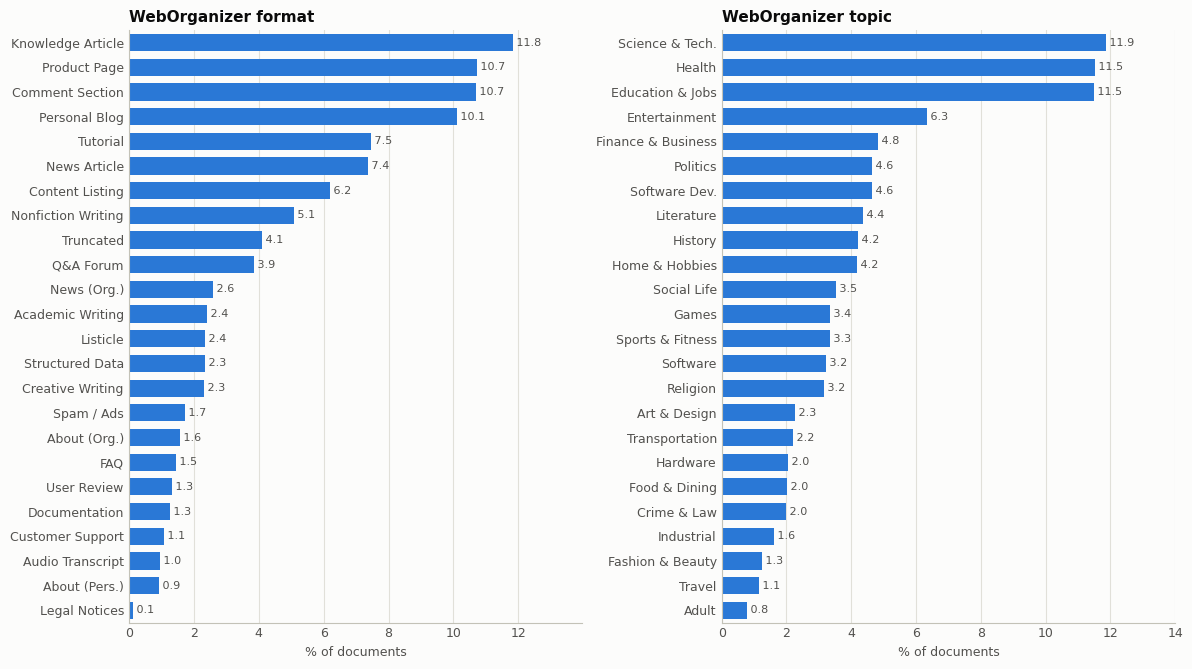

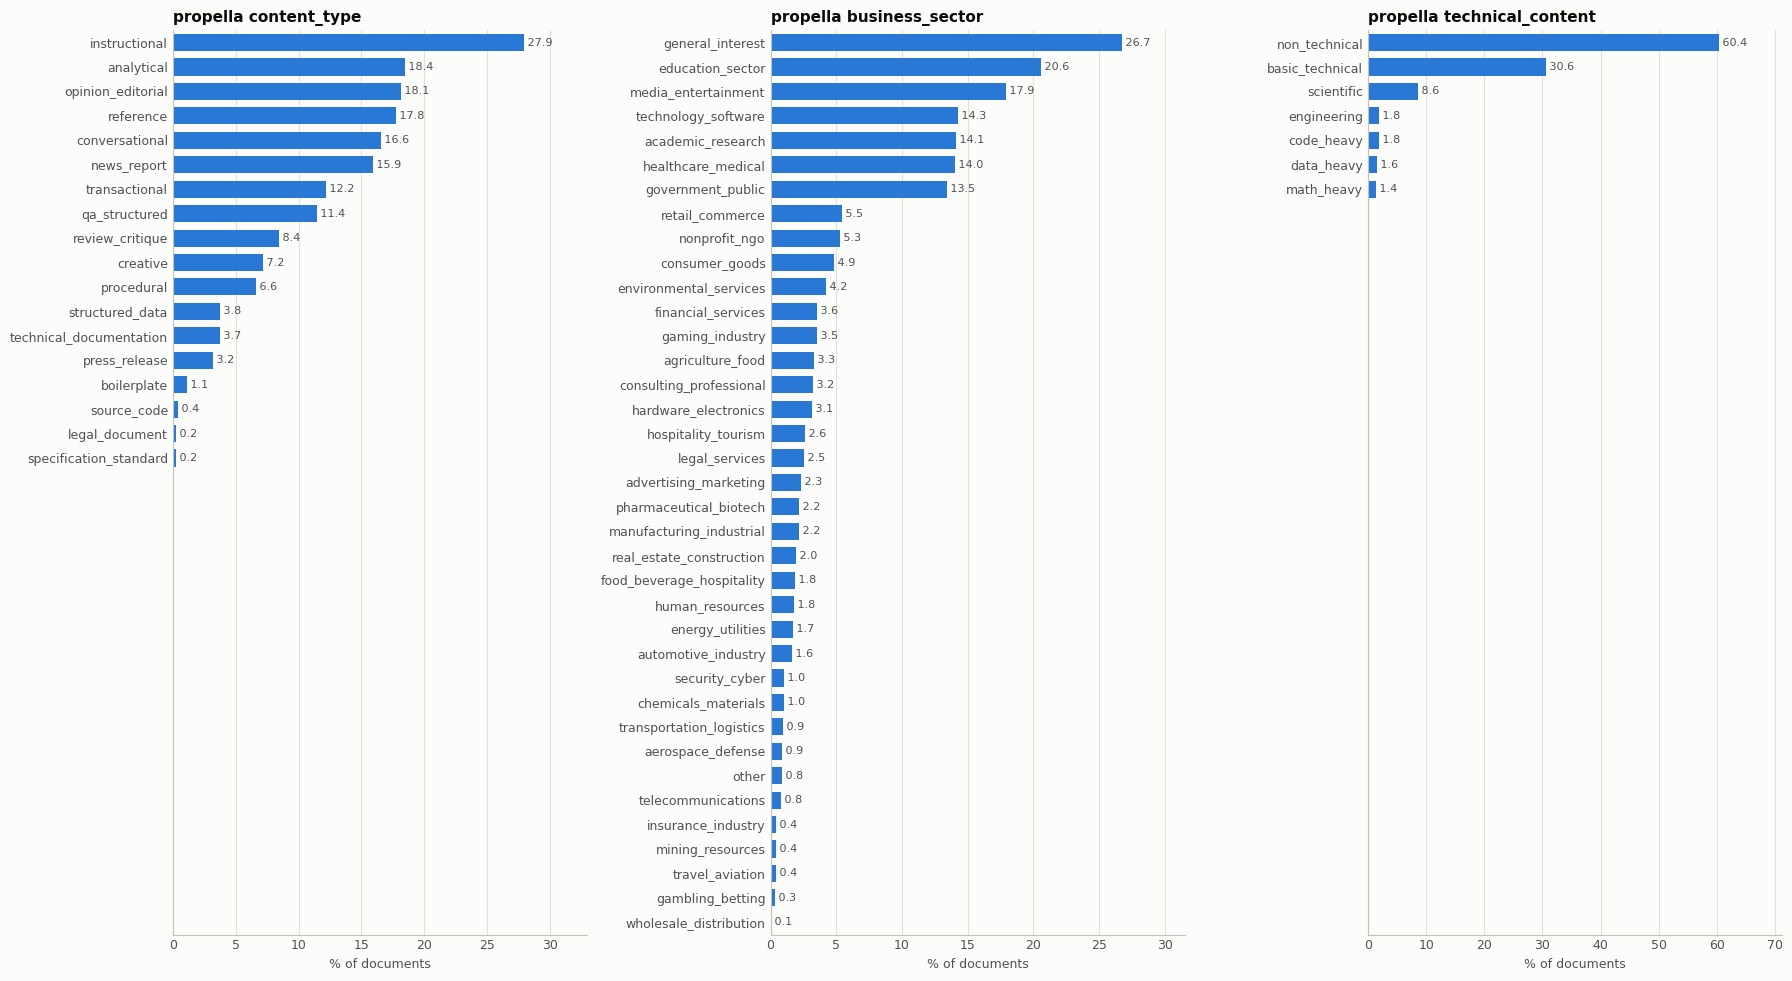

In [5]:
def plot_shares(ax: plt.Axes, shares: pd.Series, title: str, slots: int) -> None:
    """Draw label shares as horizontal bars, largest at the top.

    Args:
        ax: Axes to draw on.
        shares: Share of documents by label, in the order to draw.
        title: Panel title.
        slots: Number of bar positions in the panel. Panels drawn side by side
            get the same number, so that their bars have the same thickness.
    """
    ax.barh(range(len(shares)), shares.to_numpy() * 100, color=BAR, height=0.7)
    for position, value in enumerate(shares.to_numpy() * 100):
        ax.text(value, position, f" {value:.1f}", va="center", ha="left", color="#52514e", fontsize=8)
    ax.set_yticks(range(len(shares)))
    ax.set_yticklabels(shares.index)
    ax.set_ylim(slots - 0.5, -0.5)
    ax.set_xlim(0, shares.max() * 100 * 1.18)
    ax.set_xlabel("% of documents")
    ax.set_title(title)
    ax.xaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)


for columns in (["wo_format", "wo_topic"], PROPERTIES):
    shares = {name: label_shares(docs[name]) for name in columns}
    slots = max(len(values) for values in shares.values())
    fig, axes = plt.subplots(1, len(columns), figsize=(6 * len(columns), 1 + 0.24 * slots))
    for ax, (name, values) in zip(axes, shares.items()):
        source = "WebOrganizer " + name.removeprefix("wo_") if name.startswith("wo_") else f"propella {name}"
        plot_shares(ax, values, source, slots)
    fig.tight_layout()
    plt.show()

## 3. How association is measured

WebOrganizer gives each document one label; propella gives one or more values. To
compare them, every label and every value becomes a yes/no column over the documents
(`indicators`). For one WebOrganizer label and one propella value, `associate` then
computes, over all documents:

- **docs with both:** documents with the label and the value. **WO label docs** and
  **propella value docs** are the documents with each of them.
- **share of WO label:** of the documents with the WebOrganizer label, the share that
  also have the propella value.
- **share of propella value:** the same in the other direction.
- **lift:** how many times more often the two occur together than if they were
  independent. 1 means no connection.
- **phi:** the correlation between the two yes/no columns, from −1 to 1. 0 means no
  connection; 1 means the label and the value mark exactly the same documents. Unlike
  the shares, phi accounts for how common the label and the value are: a value that
  most documents have (`general_interest`, `non_technical`) has high shares with every
  label but a phi near 0 unless it is really over- or under-represented.
- **F1:** how well the propella value alone would stand in for the WebOrganizer label:
  the harmonic mean of the two shares. 1 means they mark the same documents.

A phi is called **significant** when it differs from 0 at level `ALPHA` after a
Bonferroni correction for the number of pairs in the comparison. The test statistic
is `n · phi²` (the chi-square statistic of the 2×2 table), so the threshold on `|phi|`
is `z / sqrt(n)`. With 10,000 documents the threshold is about 0.04: most visible
associations are significant, and the size of phi matters more than the test.

WebOrganizer labels in the label files that the classifiers never output (`Other`,
`Bad example`) and labels with no documents in the sample have no column.

In [6]:
def indicators(column: pd.Series, order: list[str] | None = None) -> pd.DataFrame:
    """Return one yes/no column per label, saying whether each document has it.

    Args:
        column: One label per document, or a list of labels per document.
        order: Column order. Labels in it that no document has are left out, and
            a label outside it is an error. None orders by frequency.

    Returns:
        A boolean frame with the documents as rows and the labels as columns.
    """
    exploded = column.explode()
    table = pd.crosstab(exploded.index, exploded).reindex(column.index, fill_value=0) > 0
    assert table.any(axis=1).all(), f"{column.name}: a document has no label"
    if order is None:
        order = table.sum().sort_values(ascending=False, kind="stable").index.tolist()
    unknown = set(table.columns) - set(order)
    if unknown:
        raise ValueError(f"{column.name} has labels outside the expected set: {sorted(unknown)}")
    return table[[label for label in order if label in table.columns]]


def associate(wo: pd.DataFrame, propella: pd.DataFrame) -> dict[str, pd.DataFrame]:
    """Measure the association of every WebOrganizer label with every propella value.

    Args:
        wo: Indicator columns of the WebOrganizer labels.
        propella: Indicator columns of the propella values, for the same documents.

    Returns:
        Frames with the WebOrganizer labels as rows and the propella values as
        columns: "docs" (documents with both), "wo_docs" and "propella_docs"
        (documents with the label and with the value), "share_of_wo",
        "share_of_propella", "lift", "phi" and "f1".
    """
    assert wo.index.equals(propella.index), "indicator frames are for different documents"
    a, b = wo.to_numpy(dtype=float), propella.to_numpy(dtype=float)
    n = len(a)
    both = a.T @ b
    n_wo, n_propella = a.sum(axis=0)[:, None], b.sum(axis=0)[None, :]
    # A label or value that every document has cannot be associated with anything.
    assert (n_wo < n).all() and (n_propella < n).all(), "a label covers every document"
    measures = {
        "docs": both,
        "wo_docs": np.broadcast_to(n_wo, both.shape),
        "propella_docs": np.broadcast_to(n_propella, both.shape),
        "share_of_wo": both / n_wo,
        "share_of_propella": both / n_propella,
        "lift": both * n / (n_wo * n_propella),
        "phi": (n * both - n_wo * n_propella) / np.sqrt(n_wo * n_propella * (n - n_wo) * (n - n_propella)),
        "f1": 2 * both / (n_wo + n_propella),
    }
    return {name: pd.DataFrame(values, index=wo.columns, columns=propella.columns) for name, values in measures.items()}


def phi_threshold(num_pairs: int, num_docs: int) -> float:
    """Return the smallest |phi| that is significant after a Bonferroni correction."""
    z = statistics.NormalDist().inv_cdf(1 - ALPHA / (2 * num_pairs))
    return z / math.sqrt(num_docs)


def pair_table(measures: dict[str, pd.DataFrame]) -> pd.DataFrame:
    """Return one row per (WebOrganizer label, propella value) pair with all measures."""
    table = pd.concat({name: frame.stack() for name, frame in measures.items()}, axis=1)
    table.index.names = ["WebOrganizer", "propella"]
    table = table.reset_index().rename(
        columns={
            "docs": "docs with both",
            "wo_docs": "WO label docs",
            "propella_docs": "propella value docs",
            "share_of_wo": "share of WO label",
            "share_of_propella": "share of propella value",
            "f1": "F1",
        }
    )
    return table.astype({"docs with both": int, "WO label docs": int, "propella value docs": int})


wo_indicators = {
    "format": indicators(docs["wo_format"], format_labels),
    "topic": indicators(docs["wo_topic"], topic_labels),
}
propella_indicators = {name: indicators(docs[name]) for name in PROPERTIES}
for name, frame in {**wo_indicators, **propella_indicators}.items():
    print(f"{name}: {frame.shape[1]} labels with documents")

format: 24 labels with documents
topic: 24 labels with documents
content_type: 18 labels with documents
business_sector: 37 labels with documents
technical_content: 7 labels with documents


### Plots and tables used in sections 4–6

Each of the three comparisons is shown the same way, by `show_comparison`:

1. **Heatmap of shares.** Rows are WebOrganizer labels, columns are propella values.
   A cell is the share of the row's documents that have the column's value; darker is
   more, and cells of 10% or more are printed in percent. Read along a row to see how
   propella describes the documents WebOrganizer gives that label. A row can add up to
   more than 100% because documents can have several values.
2. **Heatmap of phi.** The same grid, coloured by phi: blue where label and value occur
   together more than independence would give, red where less, grey where there is no
   connection. Cells with `|phi|` of 0.10 or more are printed. A dark blue cell that
   is alone in its row and its column is a one-to-one counterpart.
3. **Strongest pairs.** The `TOP_PAIRS` pairs with the highest phi among those with at
   least `MIN_PAIR_DOCS` shared documents.
4. **Best counterpart of each WebOrganizer label:** the propella value with the highest
   F1, and **best counterpart of each propella value:** the WebOrganizer label with the
   highest F1. An F1 near 1 means the two mark nearly the same documents; a low F1
   means the label has no single counterpart on the other side.

In both heatmaps the rows are in the order of the label file, and the columns are
ordered so that each value sits next to the row it is most associated with, which
puts the strongest connections near a diagonal. Labels and values with fewer than
`MIN_LABEL_DOCS` documents are left out of the heatmaps and of the best-counterpart
tables; the cell prints which.

In [7]:
def plot_heatmap(
    matrix: pd.DataFrame,
    title: str,
    *,
    cmap: LinearSegmentedColormap,
    vmin: float,
    vmax: float,
    print_from: float,
    percent: bool,
    colorbar_label: str,
    xlabel: str,
) -> None:
    """Draw a labelled heatmap, printing the cells whose absolute value is large."""
    rows, columns = matrix.shape
    fig, ax = plt.subplots(figsize=(max(8.5, 2.6 + 0.45 * columns), 2.2 + 0.3 * rows))
    # The cell borders in the background colour keep neighbouring cells apart.
    mesh = ax.pcolormesh(matrix.to_numpy(), cmap=cmap, vmin=vmin, vmax=vmax, edgecolors=SURFACE, linewidth=1.5)
    for i in range(rows):
        for j in range(columns):
            value = matrix.iat[i, j]
            if abs(value) >= print_from:
                # White text on dark cells, dark text on light ones.
                red, green, blue, _ = cmap((value - vmin) / (vmax - vmin))
                dark = 0.2126 * red + 0.7152 * green + 0.0722 * blue < 0.5
                text = f"{value * 100:.0f}" if percent else f"{value:.2f}".replace("0.", ".")
                ax.text(j + 0.5, i + 0.5, text, ha="center", va="center", fontsize=7.5, color="white" if dark else INK)
    ax.set_xticks(np.arange(columns) + 0.5)
    ax.set_xticklabels(matrix.columns, rotation=45, ha="left")
    ax.xaxis.tick_top()
    ax.xaxis.set_label_position("top")
    ax.set_xlabel(xlabel)
    ax.set_yticks(np.arange(rows) + 0.5)
    ax.set_yticklabels(matrix.index)
    ax.invert_yaxis()
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    fig.colorbar(mesh, ax=ax, label=colorbar_label, shrink=0.6, aspect=30, pad=0.02)
    fig.suptitle(title, x=0.01, ha="left", fontsize=11, fontweight="bold")
    fig.tight_layout()
    plt.show()


def best_counterparts(measures: dict[str, pd.DataFrame], of: str) -> pd.DataFrame:
    """Return the highest-F1 counterpart of each label on one side.

    Args:
        measures: Output of `associate`.
        of: "WebOrganizer" lists each WebOrganizer label with its best propella
            value; "propella" lists each propella value with its best label.
    """
    f1 = measures["f1"] if of == "WebOrganizer" else measures["f1"].T
    other = "propella" if of == "WebOrganizer" else "WebOrganizer"
    table = pair_table(measures).set_index([of, other])
    best = f1.idxmax(axis=1)
    rows = table.loc[list(zip(best.index, best))].reset_index()
    return rows.rename(columns={other: f"best {other} counterpart"})


def show_comparison(wo_name: str, property_name: str) -> dict[str, pd.DataFrame]:
    """Show the heatmaps and tables of one comparison and return its measures."""
    wo, propella = wo_indicators[wo_name], propella_indicators[property_name]
    full = associate(wo, propella)
    threshold = phi_threshold(full["phi"].size, n_docs)

    # Leave rare labels and values out of the heatmaps and the best-counterpart tables.
    keep_rows = wo.columns[wo.sum() >= MIN_LABEL_DOCS]
    keep_columns = propella.columns[propella.sum() >= MIN_LABEL_DOCS]
    for side, frame, kept in (("WebOrganizer", wo, keep_rows), ("propella", propella, keep_columns)):
        rare = frame.sum().drop(kept)
        if len(rare):
            print(f"Fewer than {MIN_LABEL_DOCS} documents, not plotted ({side}): " + ", ".join(f"{k} ({v})" for k, v in rare.items()))
    shown = {name: frame.loc[keep_rows, keep_columns] for name, frame in full.items()}
    # Order the columns by the row each is most associated with, strongest first.
    best_row = shown["phi"].to_numpy().argmax(axis=0)
    order = sorted(range(len(keep_columns)), key=lambda j: (best_row[j], -shown["phi"].iat[best_row[j], j]))
    shown = {name: frame.iloc[:, order] for name, frame in shown.items()}

    plot_heatmap(
        shown["share_of_wo"],
        f"Share of each WebOrganizer {wo_name}'s documents with each propella {property_name} value",
        cmap=SEQUENTIAL, vmin=0, vmax=1, print_from=0.10, percent=True,
        colorbar_label="share of the row's documents", xlabel=f"propella {property_name}",
    )
    limit = max(0.5, float(np.abs(shown["phi"].to_numpy()).max()))
    plot_heatmap(
        shown["phi"],
        f"Correlation (phi) between WebOrganizer {wo_name} labels and propella {property_name} values",
        cmap=DIVERGING, vmin=-limit, vmax=limit, print_from=0.10, percent=False,
        colorbar_label="phi", xlabel=f"propella {property_name}",
    )

    pairs = pair_table(full)
    significant = pairs[pairs["phi"].abs() >= threshold]
    print(
        f"{len(pairs)} pairs; |phi| >= {threshold:.3f} is significant: "
        f"{(significant['phi'] > 0).sum()} positive and {(significant['phi'] < 0).sum()} negative pairs"
    )
    print(f"\nStrongest pairs (at least {MIN_PAIR_DOCS} shared documents):")
    display(pairs[pairs["docs with both"] >= MIN_PAIR_DOCS].nlargest(TOP_PAIRS, "phi").reset_index(drop=True).round(3))
    print(f"\nBest propella {property_name} counterpart of each WebOrganizer {wo_name}:")
    display(best_counterparts(shown, "WebOrganizer").sort_values("F1", ascending=False).reset_index(drop=True).round(3))
    print(f"\nBest WebOrganizer {wo_name} counterpart of each propella {property_name} value:")
    display(best_counterparts(shown, "propella").sort_values("F1", ascending=False).reset_index(drop=True).round(3))
    return full

## 4. WebOrganizer format and propella `content_type`

Both describe what kind of document a page is, so this is where one-to-one
counterparts are most likely. What to look for:

- **Counterparts:** WebOrganizer formats whose row has one dark blue phi cell, and an
  F1 well above the others in the first best-counterpart table.
- **Formats that propella splits or merges:** rows with several medium cells (propella
  divides the format among several content types), and columns with several medium
  cells (one propella content type covers several WebOrganizer formats).
- **Formats with no counterpart:** rows that are pale throughout the phi heatmap.
  propella's `content_type` has no value for them.

Fewer than 30 documents, not plotted (WebOrganizer): Legal Notices (14)
Fewer than 30 documents, not plotted (propella): legal_document (25), specification_standard (22)


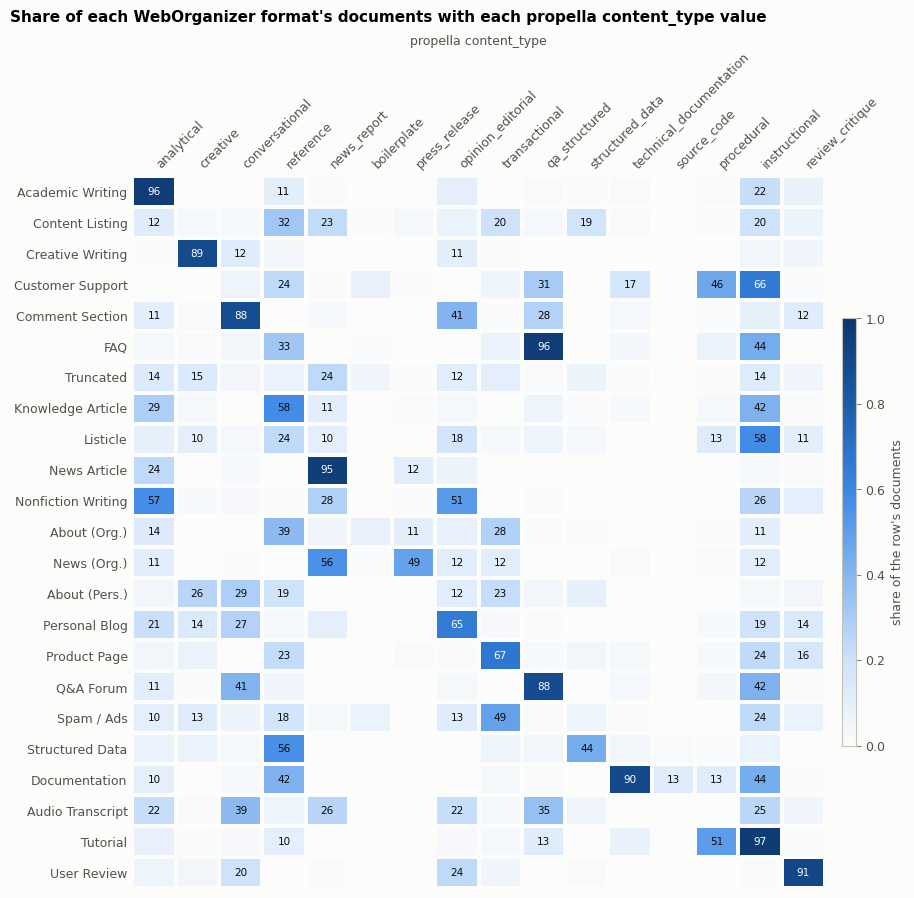

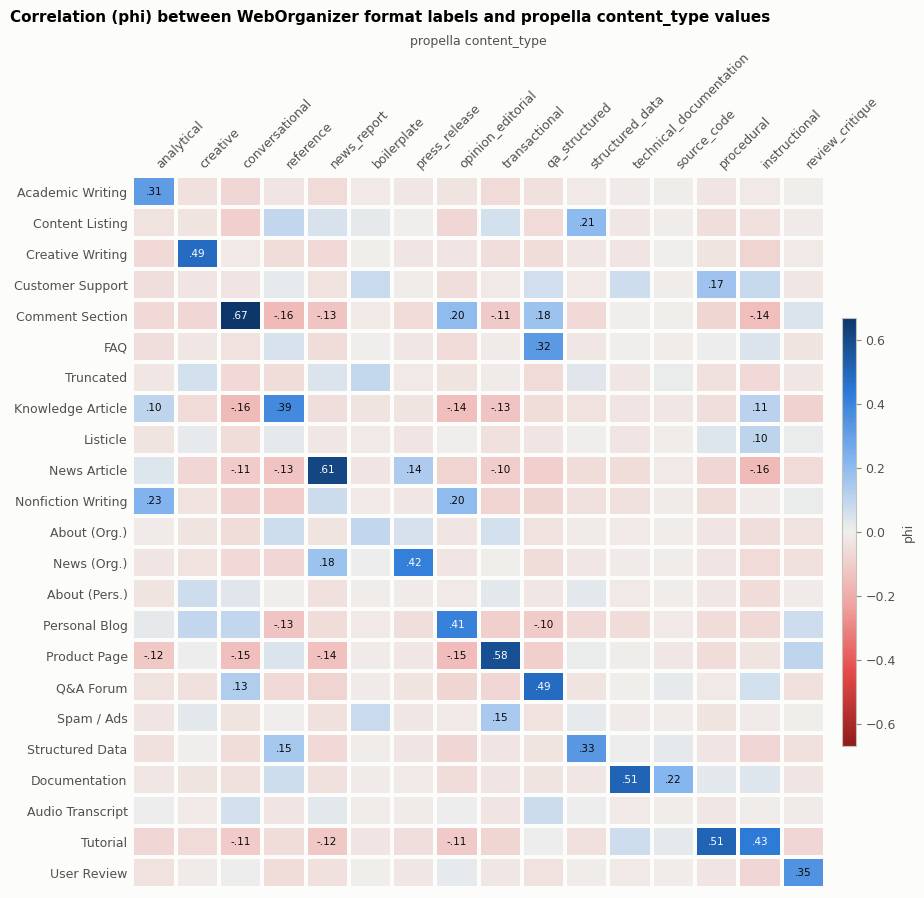

432 pairs; |phi| >= 0.039 is significant: 68 positive and 123 negative pairs

Strongest pairs (at least 20 shared documents):


,WebOrganizer,propella,docs with both,WO label docs,propella value docs,share of WO label,share of propella value,lift,phi,F1
0,Comment Section,conversational,944,1070,1656,0.882,0.570,5.328,0.667,0.693
1,News Article,news_report,704,738,1590,0.954,0.443,6.000,0.614,0.605
2,Product Page,transactional,720,1071,1219,0.672,0.591,5.515,0.583,0.629
3,Documentation,technical_documentation,113,126,373,0.897,0.303,24.044,0.512,0.453
4,Tutorial,procedural,382,747,657,0.511,0.581,7.784,0.511,0.544
5,Creative Writing,creative,207,232,719,0.892,0.288,12.409,0.489,0.435
6,Q&A Forum,qa_structured,342,387,1143,0.884,0.299,7.732,0.485,0.447
7,Tutorial,instructional,721,747,2794,0.965,0.258,3.455,0.434,0.407
8,News (Org.),press_release,126,259,319,0.486,0.395,15.250,0.422,0.436
9,Personal Blog,opinion_editorial,657,1011,1814,0.650,0.362,3.582,0.408,0.465



Best propella content_type counterpart of each WebOrganizer format:


,WebOrganizer,best propella counterpart,docs with both,WO label docs,propella value docs,share of WO label,share of propella value,lift,phi,F1
0,Comment Section,conversational,944,1070,1656,0.882,0.570,5.328,0.667,0.693
1,Product Page,transactional,720,1071,1219,0.672,0.591,5.515,0.583,0.629
2,News Article,news_report,704,738,1590,0.954,0.443,6.000,0.614,0.605
3,Tutorial,procedural,382,747,657,0.511,0.581,7.784,0.511,0.544
4,Personal Blog,opinion_editorial,657,1011,1814,0.650,0.362,3.582,0.408,0.465
5,Knowledge Article,reference,686,1184,1777,0.579,0.386,3.261,0.385,0.463
6,Documentation,technical_documentation,113,126,373,0.897,0.303,24.044,0.512,0.453
7,Q&A Forum,qa_structured,342,387,1143,0.884,0.299,7.732,0.485,0.447
8,News (Org.),press_release,126,259,319,0.486,0.395,15.250,0.422,0.436
9,Creative Writing,creative,207,232,719,0.892,0.288,12.409,0.489,0.435



Best WebOrganizer format counterpart of each propella content_type value:


,propella,best WebOrganizer counterpart,docs with both,WO label docs,propella value docs,share of WO label,share of propella value,lift,phi,F1
0,conversational,Comment Section,944,1070,1656,0.882,0.570,5.328,0.667,0.693
1,transactional,Product Page,720,1071,1219,0.672,0.591,5.515,0.583,0.629
2,news_report,News Article,704,738,1590,0.954,0.443,6.000,0.614,0.605
3,procedural,Tutorial,382,747,657,0.511,0.581,7.784,0.511,0.544
4,opinion_editorial,Personal Blog,657,1011,1814,0.650,0.362,3.582,0.408,0.465
5,reference,Knowledge Article,686,1184,1777,0.579,0.386,3.261,0.385,0.463
6,technical_documentation,Documentation,113,126,373,0.897,0.303,24.044,0.512,0.453
7,qa_structured,Q&A Forum,342,387,1143,0.884,0.299,7.732,0.485,0.447
8,press_release,News (Org.),126,259,319,0.486,0.395,15.250,0.422,0.436
9,creative,Creative Writing,207,232,719,0.892,0.288,12.409,0.489,0.435


In [8]:
format_vs_content_type = show_comparison("format", "content_type")

## 5. WebOrganizer topic and propella `business_sector`

Both describe what a page is about, but from different angles: WebOrganizer's topics
are subject areas, propella's sectors are industries. propella also has
`general_interest` for content without a sector, which covers a large part of the
sample; expect it to have high shares in many rows of the first heatmap and to be
tied to topics that are not industries. propella has many more sectors than
WebOrganizer has topics, so several sectors can share one topic.

Fewer than 30 documents, not plotted (propella): wholesale_distribution (6)


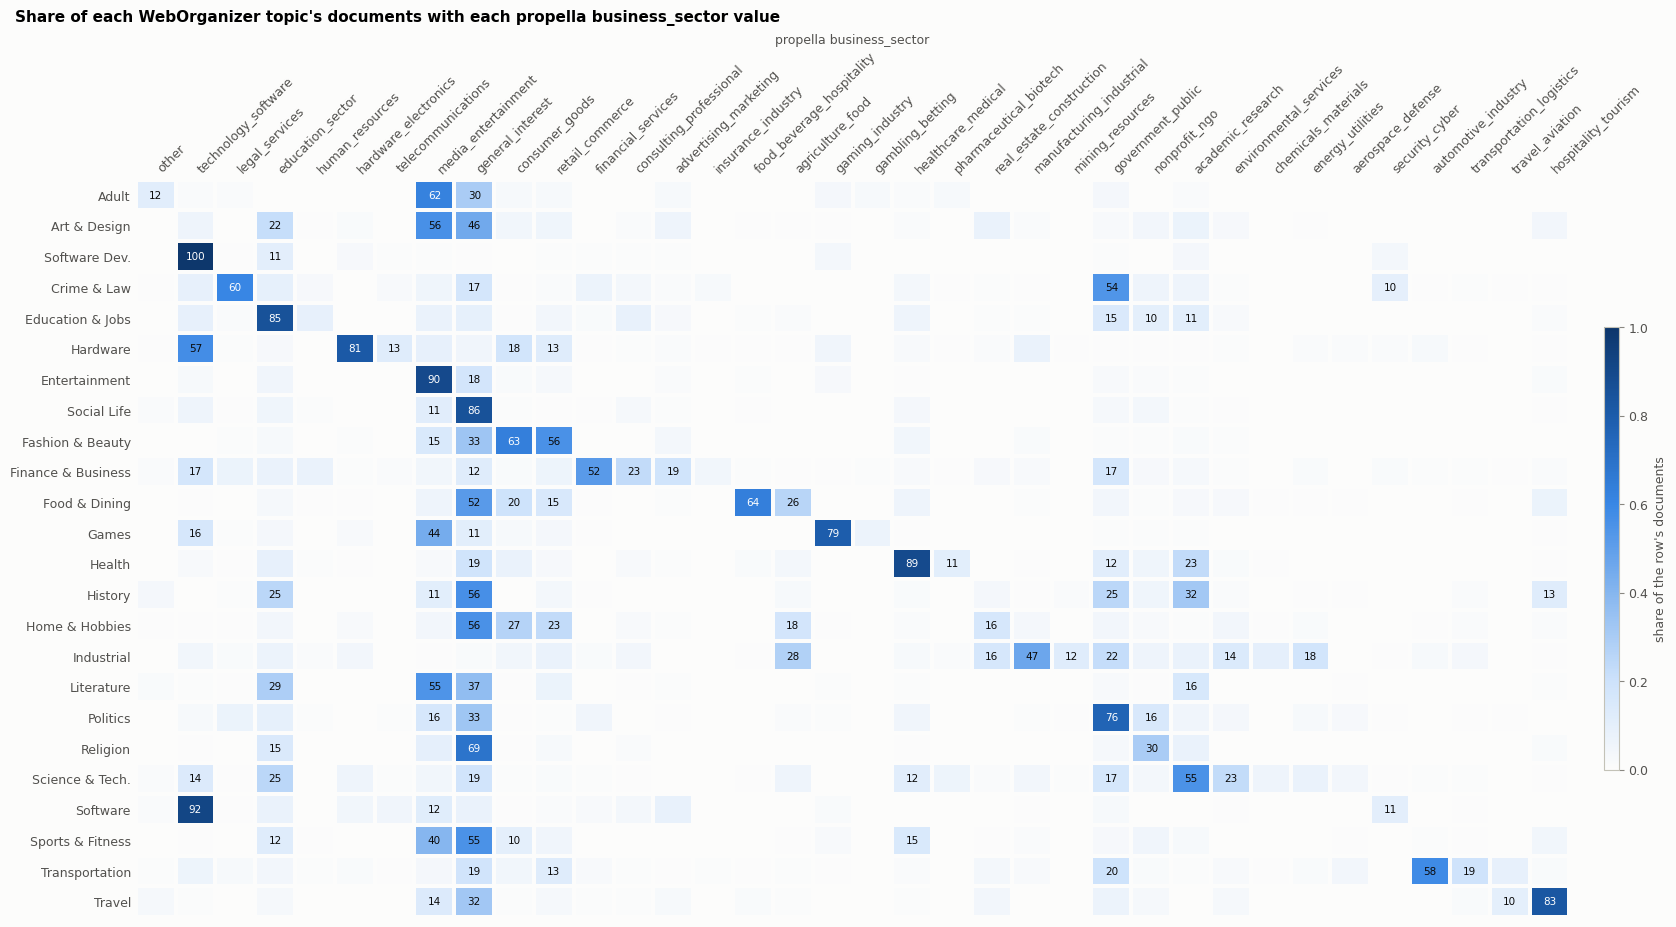

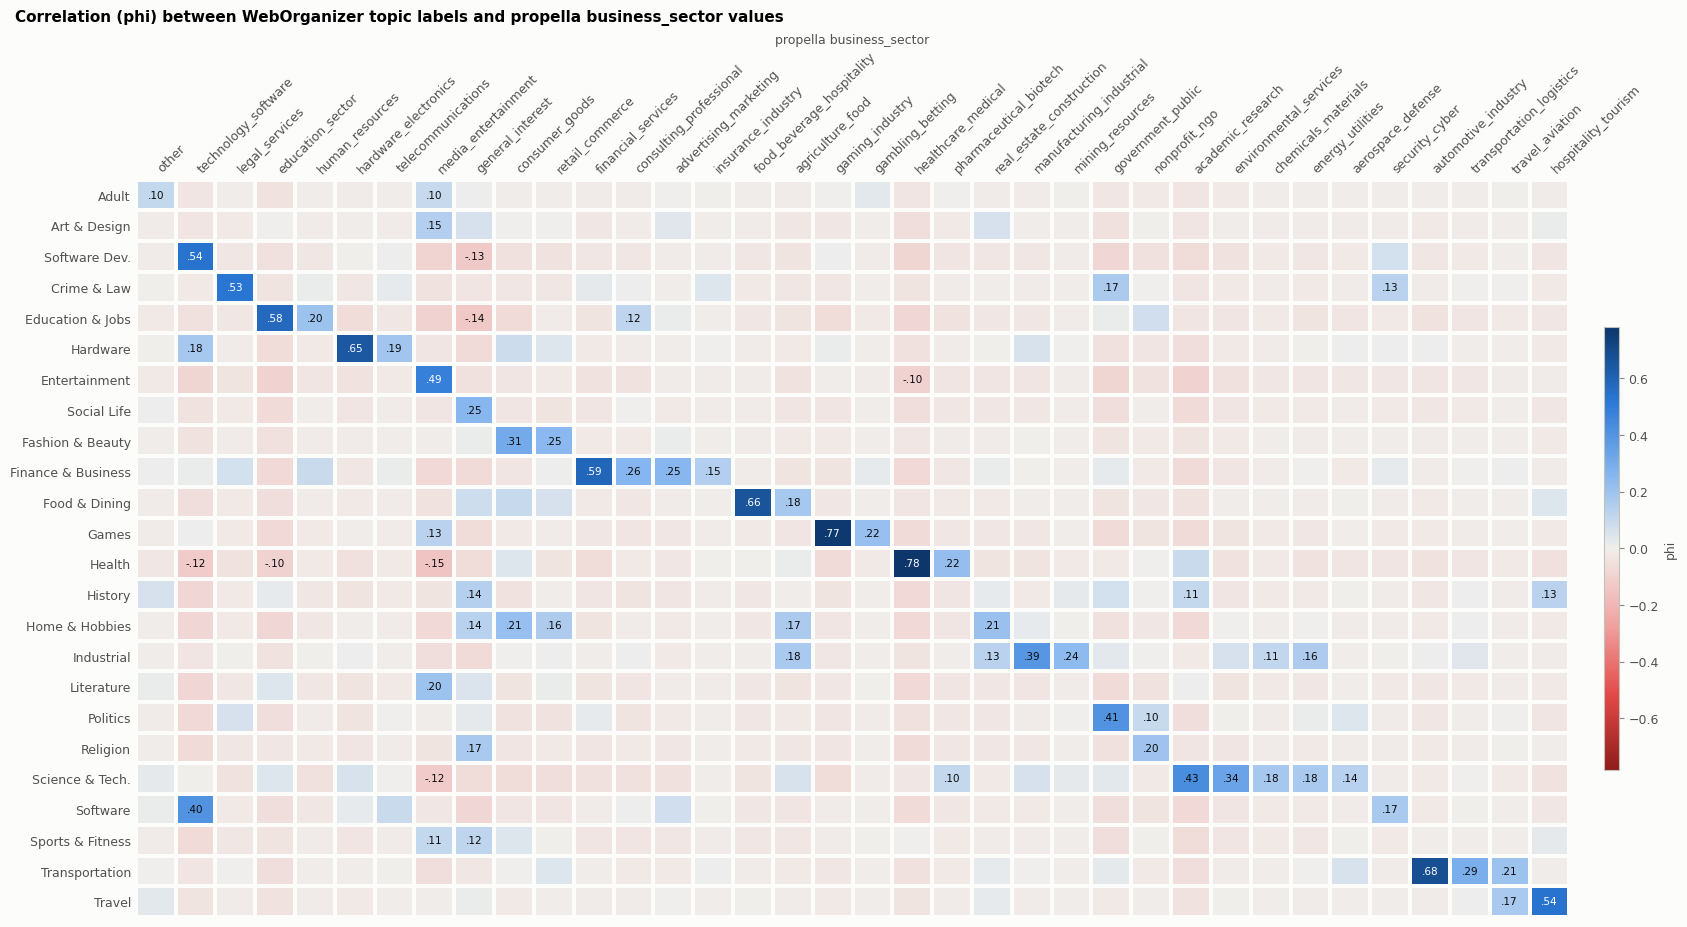

888 pairs; |phi| >= 0.040 is significant: 95 positive and 137 negative pairs

Strongest pairs (at least 20 shared documents):


,WebOrganizer,propella,docs with both,WO label docs,propella value docs,share of WO label,share of propella value,lift,phi,F1
0,Health,healthcare_medical,1028,1153,1402,0.892,0.733,6.359,0.781,0.805
1,Games,gaming_industry,267,336,354,0.795,0.754,22.448,0.766,0.774
2,Transportation,automotive_industry,129,221,161,0.584,0.801,36.255,0.678,0.675
3,Food & Dining,food_beverage_hospitality,129,203,183,0.635,0.705,34.725,0.663,0.668
4,Hardware,hardware_electronics,166,204,315,0.814,0.527,25.833,0.646,0.640
5,Finance & Business,financial_services,251,484,357,0.519,0.703,14.526,0.587,0.597
6,Education & Jobs,education_sector,979,1149,2059,0.852,0.475,4.138,0.576,0.610
7,Travel,hospitality_tourism,95,115,263,0.826,0.361,31.410,0.539,0.503
8,Software Dev.,technology_software,461,463,1427,0.996,0.323,6.977,0.537,0.488
9,Crime & Law,legal_services,121,200,251,0.605,0.482,24.104,0.530,0.537



Best propella business_sector counterpart of each WebOrganizer topic:


,WebOrganizer,best propella counterpart,docs with both,WO label docs,propella value docs,share of WO label,share of propella value,lift,phi,F1
0,Health,healthcare_medical,1028,1153,1402,0.892,0.733,6.359,0.781,0.805
1,Games,gaming_industry,267,336,354,0.795,0.754,22.448,0.766,0.774
2,Transportation,automotive_industry,129,221,161,0.584,0.801,36.255,0.678,0.675
3,Food & Dining,food_beverage_hospitality,129,203,183,0.635,0.705,34.725,0.663,0.668
4,Hardware,hardware_electronics,166,204,315,0.814,0.527,25.833,0.646,0.640
5,Education & Jobs,education_sector,979,1149,2059,0.852,0.475,4.138,0.576,0.610
6,Finance & Business,financial_services,251,484,357,0.519,0.703,14.526,0.587,0.597
7,Crime & Law,legal_services,121,200,251,0.605,0.482,24.104,0.530,0.537
8,Science & Tech.,academic_research,654,1187,1412,0.551,0.463,3.902,0.432,0.503
9,Travel,hospitality_tourism,95,115,263,0.826,0.361,31.410,0.539,0.503



Best WebOrganizer topic counterpart of each propella business_sector value:


,propella,best WebOrganizer counterpart,docs with both,WO label docs,propella value docs,share of WO label,share of propella value,lift,phi,F1
0,healthcare_medical,Health,1028,1153,1402,0.892,0.733,6.359,0.781,0.805
1,gaming_industry,Games,267,336,354,0.795,0.754,22.448,0.766,0.774
2,automotive_industry,Transportation,129,221,161,0.584,0.801,36.255,0.678,0.675
3,food_beverage_hospitality,Food & Dining,129,203,183,0.635,0.705,34.725,0.663,0.668
4,hardware_electronics,Hardware,166,204,315,0.814,0.527,25.833,0.646,0.640
5,education_sector,Education & Jobs,979,1149,2059,0.852,0.475,4.138,0.576,0.610
6,financial_services,Finance & Business,251,484,357,0.519,0.703,14.526,0.587,0.597
7,legal_services,Crime & Law,121,200,251,0.605,0.482,24.104,0.530,0.537
8,academic_research,Science & Tech.,654,1187,1412,0.551,0.463,3.902,0.432,0.503
9,hospitality_tourism,Travel,95,115,263,0.826,0.361,31.410,0.539,0.503


In [9]:
topic_vs_business_sector = show_comparison("topic", "business_sector")

## 6. WebOrganizer topic and propella `technical_content`

`technical_content` is not a topic: it says what kind of specialised content a
document has and how much (code, mathematics, scientific, data, engineering, some, or
none). Most documents are `non_technical`. The question here is which topics the
technical kinds concentrate in, for example whether `code_heavy` is confined to
*Software Dev.* and where `scientific` goes. With only seven values, most topics
cannot have a counterpart of their own, so the first best-counterpart table mainly
shows `non_technical`; the second one, per propella value, is the informative one.

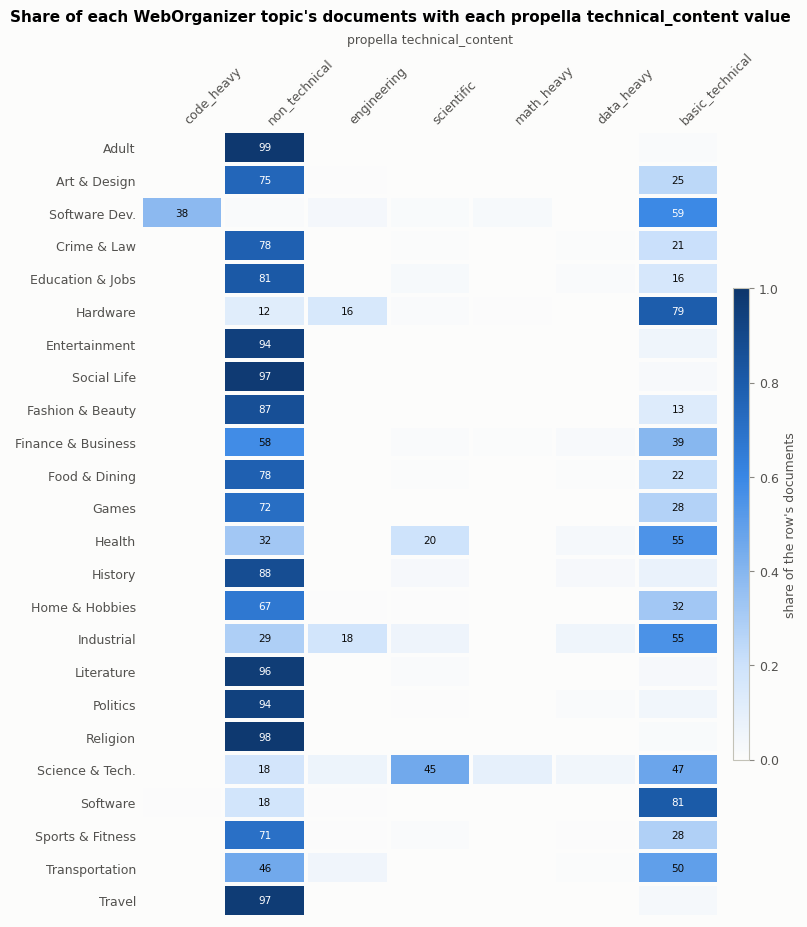

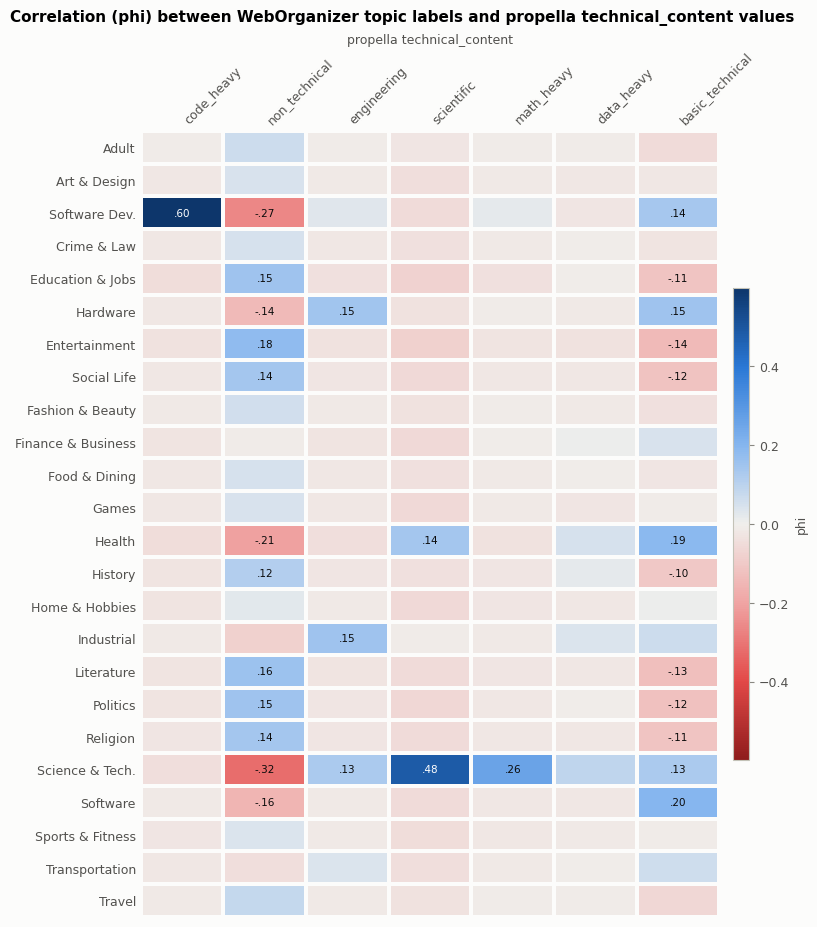

168 pairs; |phi| >= 0.036 is significant: 34 positive and 41 negative pairs

Strongest pairs (at least 20 shared documents):


,WebOrganizer,propella,docs with both,WO label docs,propella value docs,share of WO label,share of propella value,lift,phi,F1
0,Software Dev.,code_heavy,178,463,185,0.384,0.962,20.781,0.598,0.549
1,Science & Tech.,scientific,540,1187,858,0.455,0.629,5.302,0.484,0.528
2,Science & Tech.,math_heavy,115,1187,138,0.097,0.833,7.020,0.261,0.174
3,Software,basic_technical,260,322,3065,0.807,0.085,2.634,0.198,0.154
4,Health,basic_technical,632,1153,3065,0.548,0.206,1.788,0.189,0.300
5,Entertainment,non_technical,598,634,6041,0.943,0.099,1.561,0.180,0.179
6,Literature,non_technical,419,436,6041,0.961,0.069,1.591,0.156,0.129
7,Education & Jobs,non_technical,934,1149,6041,0.813,0.155,1.346,0.154,0.260
8,Industrial,engineering,29,161,185,0.180,0.157,9.736,0.153,0.168
9,Hardware,basic_technical,162,204,3065,0.794,0.053,2.591,0.153,0.099



Best propella technical_content counterpart of each WebOrganizer topic:


,WebOrganizer,best propella counterpart,docs with both,WO label docs,propella value docs,share of WO label,share of propella value,lift,phi,F1
0,Software Dev.,code_heavy,178,463,185,0.384,0.962,20.781,0.598,0.549
1,Science & Tech.,scientific,540,1187,858,0.455,0.629,5.302,0.484,0.528
2,Health,basic_technical,632,1153,3065,0.548,0.206,1.788,0.189,0.300
3,Education & Jobs,non_technical,934,1149,6041,0.813,0.155,1.346,0.154,0.260
4,Entertainment,non_technical,598,634,6041,0.943,0.099,1.561,0.180,0.179
5,Industrial,engineering,29,161,185,0.180,0.157,9.736,0.153,0.168
6,Hardware,engineering,32,204,185,0.157,0.173,8.479,0.148,0.165
7,Software,basic_technical,260,322,3065,0.807,0.085,2.634,0.198,0.154
8,Politics,non_technical,435,463,6041,0.940,0.072,1.555,0.151,0.134
9,Literature,non_technical,419,436,6041,0.961,0.069,1.591,0.156,0.129



Best WebOrganizer topic counterpart of each propella technical_content value:


,propella,best WebOrganizer counterpart,docs with both,WO label docs,propella value docs,share of WO label,share of propella value,lift,phi,F1
0,code_heavy,Software Dev.,178,463,185,0.384,0.962,20.781,0.598,0.549
1,scientific,Science & Tech.,540,1187,858,0.455,0.629,5.302,0.484,0.528
2,basic_technical,Health,632,1153,3065,0.548,0.206,1.788,0.189,0.300
3,non_technical,Education & Jobs,934,1149,6041,0.813,0.155,1.346,0.154,0.260
4,math_heavy,Science & Tech.,115,1187,138,0.097,0.833,7.020,0.261,0.174
5,engineering,Industrial,29,161,185,0.180,0.157,9.736,0.153,0.168
6,data_heavy,Science & Tech.,56,1187,157,0.047,0.357,3.005,0.093,0.083


In [10]:
topic_vs_technical_content = show_comparison("topic", "technical_content")

## 7. How well do the propella values predict the WebOrganizer labels?

Sections 4–6 look at one label and one value at a time. This section asks how much of
a WebOrganizer label set can be recovered from a propella property as a whole,
including combinations of values. For each WebOrganizer classifier and each propella
property (and all three properties together), a logistic regression predicts the
WebOrganizer label from the document's propella values. It is evaluated with
`N_FOLDS`-fold cross-validation, so every document is predicted by a model that did
not see it.

- **accuracy:** share of documents whose WebOrganizer label is predicted correctly.
- **baseline:** the accuracy of always predicting the most common label. A property
  with no connection to the labels stays at the baseline.
- **macro F1:** the average F1 over the labels, where every label counts the same
  however rare it is. It shows whether the rare labels are recovered too.

This is a lower bound on the shared information, from a simple model, and it is in
one direction only: it does not say how well WebOrganizer labels would predict
propella values. The cell fits 40 models and takes a couple of minutes.

In [11]:
def predict_labels(features: pd.DataFrame, target: pd.Series) -> np.ndarray:
    """Return cross-validated predictions of a WebOrganizer label from indicator columns."""
    folds = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    model = LogisticRegression(max_iter=2000)
    return cross_val_predict(model, features.to_numpy(dtype=float), target.to_numpy(), cv=folds)


all_properties = pd.concat(propella_indicators, axis=1)
feature_sets = {**propella_indicators, "all three properties": all_properties}
targets = {"format": docs["wo_format"], "topic": docs["wo_topic"]}

predictions = {}
prediction_rows = []
for target_name, target in targets.items():
    for feature_name, features in feature_sets.items():
        predicted = predict_labels(features, target)
        predictions[target_name, feature_name] = predicted
        prediction_rows.append(
            {
                "WebOrganizer": target_name,
                "predicted from propella": feature_name,
                "accuracy": (predicted == target.to_numpy()).mean(),
                "baseline": target.value_counts(normalize=True).iloc[0],
                "macro F1": f1_score(target, predicted, average="macro", zero_division=0),
            }
        )
prediction_table = pd.DataFrame(prediction_rows)
display(prediction_table.round(3))

,WebOrganizer,predicted from propella,accuracy,baseline,macro F1
0,format,content_type,0.485,0.118,0.320
1,format,business_sector,0.243,0.118,0.110
2,format,technical_content,0.158,0.118,0.066
3,format,all three properties,0.507,0.118,0.378
4,topic,content_type,0.242,0.119,0.112
5,topic,business_sector,0.542,0.119,0.446
6,topic,technical_content,0.229,0.119,0.076
7,topic,all three properties,0.592,0.119,0.510


**Plot.** F1 of each WebOrganizer label when it is predicted from all three propella
properties together, with the number of documents after each label name. Labels with
a long bar are ones propella's values identify; labels with a bar near zero are
distinctions that WebOrganizer makes and these three propella properties do not.
Labels with few documents have unstable values.

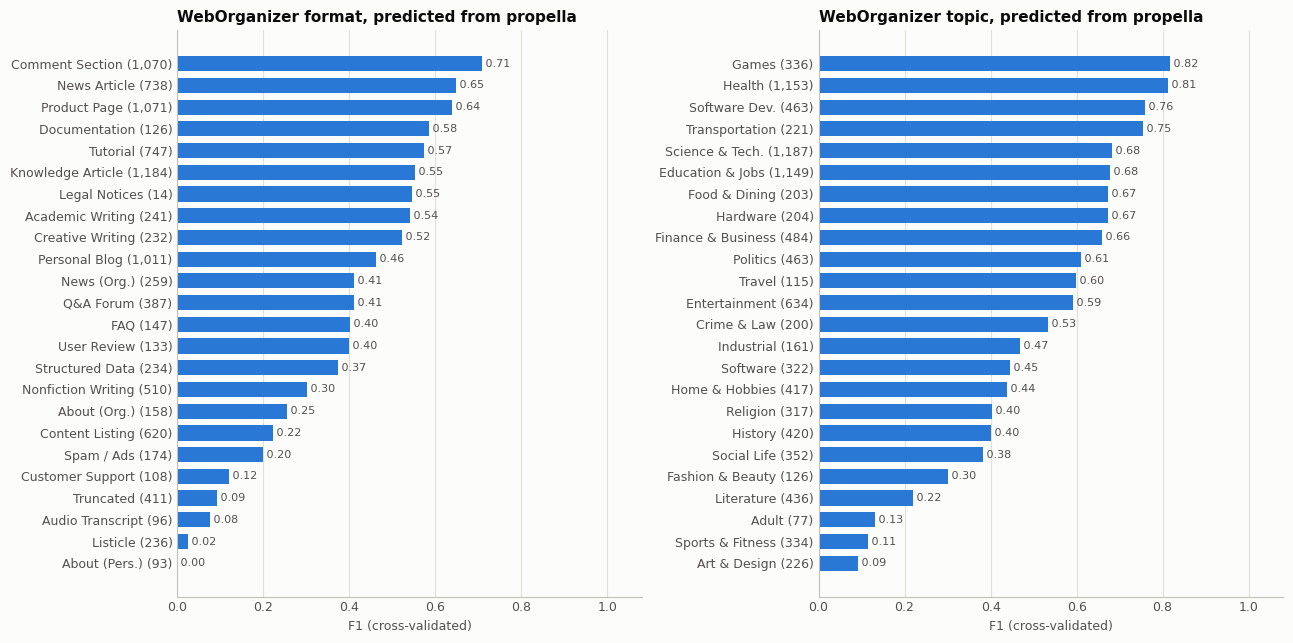

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
for ax, (target_name, target) in zip(axes, targets.items()):
    predicted = predictions[target_name, "all three properties"]
    labels = target.value_counts().index.tolist()
    scores = f1_score(target, predicted, labels=labels, average=None, zero_division=0)
    per_label = pd.Series(scores, index=labels).sort_values(ascending=False, kind="stable")
    counts = target.value_counts()
    ax.barh(range(len(per_label)), per_label.to_numpy(), color=BAR, height=0.7)
    for position, value in enumerate(per_label.to_numpy()):
        ax.text(value, position, f" {value:.2f}", va="center", ha="left", color="#52514e", fontsize=8)
    ax.set_yticks(range(len(per_label)))
    ax.set_yticklabels([f"{label} ({counts[label]:,})" for label in per_label.index])
    ax.invert_yaxis()
    ax.set_xlim(0, 1.08)
    ax.set_xlabel("F1 (cross-validated)")
    ax.set_title(f"WebOrganizer {target_name}, predicted from propella")
    ax.xaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
fig.tight_layout()
plt.show()

## 8. Summary of all six pairings

One row per combination of a WebOrganizer classifier and a propella property; the
three pairings of sections 4–6 are marked. The other three are included to check
that the expected pairings are the strong ones, for example that format is tied to
`content_type` more than to `business_sector`.

- **significant positive pairs:** label and value pairs that occur together more than
  independence would give (section 3), out of **pairs**.
- **pairs with phi ≥ 0.3:** pairs with a strong connection.
- **strongest pair** and its **phi**.
- **WO labels with a counterpart:** WebOrganizer labels whose best propella value has
  an F1 of at least 0.5, among labels and values with at least `MIN_LABEL_DOCS`
  documents.
- **accuracy** and **baseline:** from section 7.

In [13]:
FOCUS = {("format", "content_type"), ("topic", "business_sector"), ("topic", "technical_content")}

summary_rows = []
for wo_name, wo in wo_indicators.items():
    for property_name, propella in propella_indicators.items():
        measures = associate(wo, propella)
        pairs = pair_table(measures)
        threshold = phi_threshold(len(pairs), n_docs)
        strongest = pairs.loc[pairs["phi"].idxmax()]
        frequent = measures["f1"].loc[wo.columns[wo.sum() >= MIN_LABEL_DOCS], propella.columns[propella.sum() >= MIN_LABEL_DOCS]]
        accuracy = prediction_table.query("WebOrganizer == @wo_name and `predicted from propella` == @property_name").iloc[0]
        summary_rows.append(
            {
                "WebOrganizer": wo_name,
                "propella": property_name,
                "sections 4-6": "yes" if (wo_name, property_name) in FOCUS else "",
                "pairs": len(pairs),
                "significant positive pairs": int((pairs["phi"] >= threshold).sum()),
                "pairs with phi >= 0.3": int((pairs["phi"] >= 0.3).sum()),
                "strongest pair": f"{strongest['WebOrganizer']} / {strongest['propella']}",
                "phi": strongest["phi"],
                "WO labels with a counterpart": f"{int((frequent.max(axis=1) >= 0.5).sum())} of {len(frequent)}",
                "accuracy": accuracy["accuracy"],
                "baseline": accuracy["baseline"],
            }
        )
display(pd.DataFrame(summary_rows).round(3))

,WebOrganizer,propella,sections 4-6,pairs,significant positive pairs,pairs with phi >= 0.3,strongest pair,phi,WO labels with a counterpart,accuracy,baseline
0,format,content_type,yes,432,68,16,Comment Section / conversational,0.667,4 of 23,0.485,0.118
1,format,business_sector,,888,71,2,Product Page / retail_commerce,0.315,0 of 23,0.243,0.118
2,format,technical_content,,168,30,1,Documentation / code_heavy,0.364,0 of 23,0.158,0.118
3,topic,content_type,,432,70,1,Software Dev. / technical_documentation,0.459,0 of 24,0.242,0.119
4,topic,business_sector,yes,888,95,17,Health / healthcare_medical,0.781,10 of 24,0.542,0.119
5,topic,technical_content,yes,168,34,2,Software Dev. / code_heavy,0.598,2 of 24,0.229,0.119
